<a href="https://colab.research.google.com/github/Saransh-Basu-01/50-Ml-Projects-to-understand-LLMs/blob/main/Project_16_Softmax_Probability_Distributions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F

from transformers import AutoModelForCausalLM, GPT2Tokenizer

# Part 1: Softmax in NumPy and PyTorch


## Task_1:
- Transform the following list of numbers into a softmax distribution
by translating Equation 4.8 into NumPy code. Print the softmax
probabilities and confirm that they sum to 1.
z = [1,1.1,2,3,5,6,6.1]
Repeat the calculation using PyTorch’s softmax function. Be
mindful of datatypes. Print out the softmax probabilities and
confirm that they match the NumPy output.
Show both results in a graph as in Figure 4.2.

In [ ]:
z = [1,1.1,2,3,5,6,6.1]
def softmax(z):
    z = np.asarray(z, dtype=np.float64)
    z = z - np.max(z)
    exp_z = np.exp(z)
    return exp_z / np.sum(exp_z)
softmax(z)

array([0.00263681, 0.00291413, 0.0071676 , 0.01948356, 0.1439651 ,
       0.39133772, 0.43249507])

In [ ]:
zTorch = torch.tensor(z,dtype=torch.float32)

# using a function
zTorch_sm = F.softmax(zTorch,dim=-1)
zTorch_sm

tensor([0.0026, 0.0029, 0.0072, 0.0195, 0.1440, 0.3913, 0.4325])

In [ ]:
num = np.exp(z)
den = np.sum( np.exp(z) )
sm = num / den

print(sm)
print(np.sum(sm))

[0.00263681 0.00291413 0.0071676  0.01948356 0.1439651  0.39133772
 0.43249507]
1.0


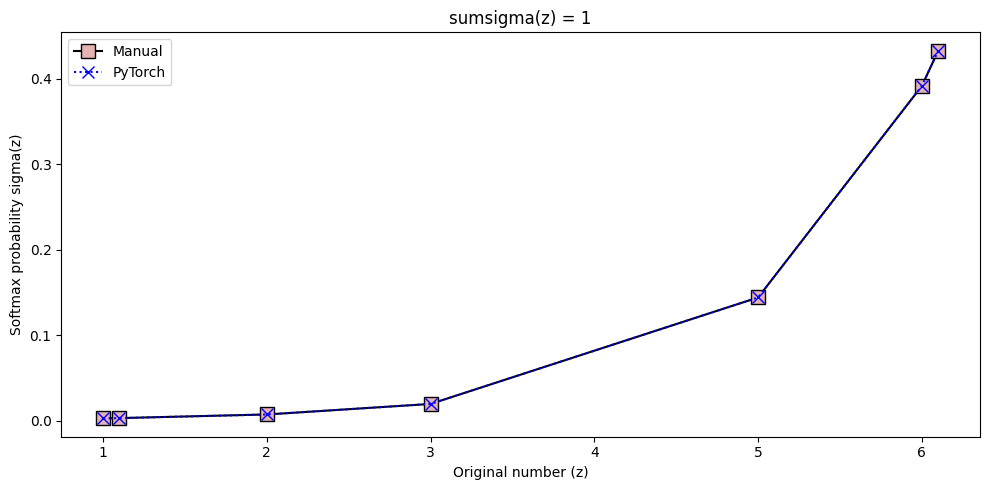

In [ ]:

# compare
plt.figure(figsize=(10,5))

plt.plot(z,sm,'ks-',markerfacecolor=[.9,.7,.7],markersize=10,label='Manual')
plt.plot(z,zTorch_sm,'bx:',markersize=8,label='PyTorch')
plt.legend()

plt.gca().set(xlabel='Original number (z)',ylabel='Softmax probability sigma(z)',
              title='sumsigma(z) = %g' %np.sum(sm))

plt.tight_layout()
plt.savefig('ch4_proj16_part1.png')
plt.show()

# Part_2:Temperature

## Task_1
- create a PyTorch tensor comprising 55 linearly spaced numbers from-5 to 5. Transform that tensor into softmax probabilities using four
temperature values (.3, .6, 1, 1.4), and visualize the results as in
Figure 4.3.

In [ ]:
x=torch.linspace(-5,5,55)
for i,temp in enumerate([0.3,0.6,1,1.4]):
  sm=F.softmax(x/temp,dim=-1)
  print(f"{i}={sm}")

0=tensor([1.5376e-15, 2.8505e-15, 5.2845e-15, 9.7968e-15, 1.8162e-14, 3.3670e-14,
        6.2421e-14, 1.1572e-13, 2.1454e-13, 3.9772e-13, 7.3734e-13, 1.3669e-12,
        2.5341e-12, 4.6980e-12, 8.7096e-12, 1.6147e-11, 2.9934e-11, 5.5494e-11,
        1.0288e-10, 1.9073e-10, 3.5359e-10, 6.5551e-10, 1.2152e-09, 2.2529e-09,
        4.1766e-09, 7.7430e-09, 1.4355e-08, 2.6612e-08, 4.9335e-08, 9.1462e-08,
        1.6956e-07, 3.1435e-07, 5.8276e-07, 1.0804e-06, 2.0029e-06, 3.7131e-06,
        6.8837e-06, 1.2762e-05, 2.3659e-05, 4.3860e-05, 8.1312e-05, 1.5074e-04,
        2.7946e-04, 5.1809e-04, 9.6048e-04, 1.7806e-03, 3.3011e-03, 6.1198e-03,
        1.1345e-02, 2.1033e-02, 3.8993e-02, 7.2288e-02, 1.3401e-01, 2.4845e-01,
        4.6059e-01])
1=tensor([1.5343e-08, 2.0891e-08, 2.8445e-08, 3.8729e-08, 5.2733e-08, 7.1800e-08,
        9.7761e-08, 1.3311e-07, 1.8124e-07, 2.4677e-07, 3.3599e-07, 4.5748e-07,
        6.2289e-07, 8.4812e-07, 1.1548e-06, 1.5723e-06, 2.1408e-06, 2.9149e-06,
        3.9688e

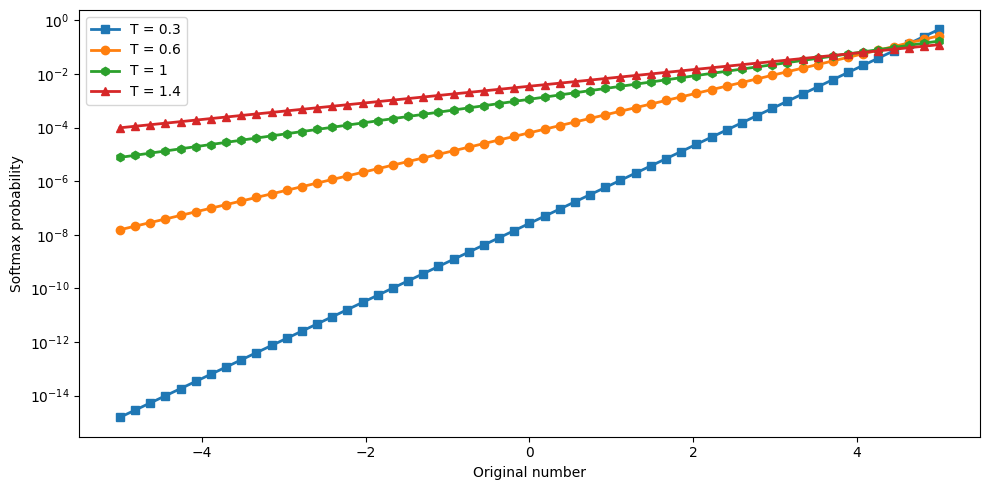

In [ ]:
x = torch.linspace(-5,5,55)

shapes = 'soh^'

plt.figure(figsize=(10,5))
for i,temp in enumerate([.3,.6,1,1.4]):
  sm = F.softmax(x/temp,dim=-1)
  plt.plot(x,sm,shapes[i]+'-',linewidth=2,label='T = %g' %temp)

plt.legend()
plt.gca().set(xlabel='Original number',ylabel='Softmax probability')
plt.yscale('log')

plt.tight_layout()
plt.show()

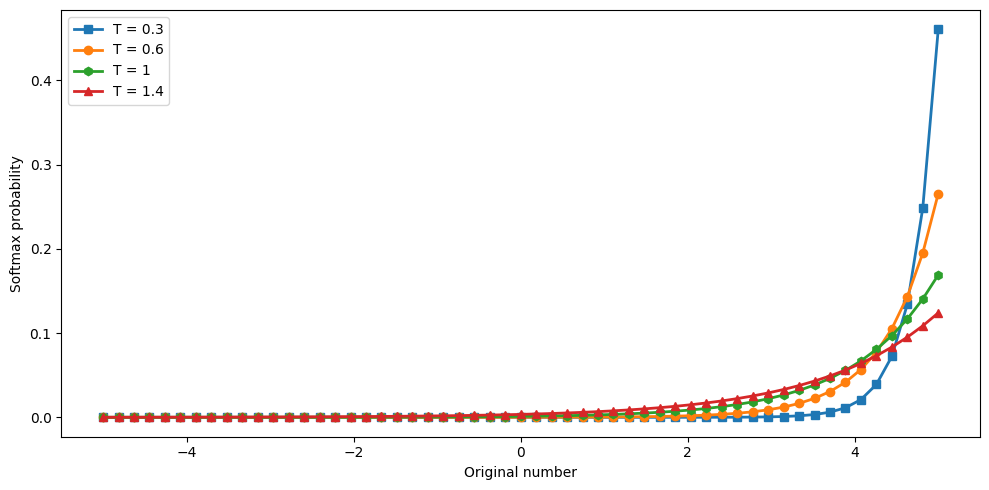

In [ ]:
x = torch.linspace(-5,5,55)

shapes = 'soh^'

plt.figure(figsize=(10,5))
for i,temp in enumerate([.3,.6,1,1.4]):
  sm = F.softmax(x/temp,dim=-1)
  plt.plot(x,sm,shapes[i]+'-',linewidth=2,label='T = %g' %temp)

plt.legend()
plt.gca().set(xlabel='Original number',ylabel='Softmax probability')
# plt.yscale('log')

plt.tight_layout()
plt.show()

# Part 3: Softmax LLM output logits

## Task_1:
- Import the GPT-2-small and GPT-2-large models. Use different vari
able names for the models, although they use the same tokenizer, so
you only need to import that once. Use the num_parameters at
tribute to print the number of parameters in the two models.

In [ ]:
# load pretrained GPT-2 model and tokenizer
gpt2_small = AutoModelForCausalLM.from_pretrained('gpt2')
gpt2_large = AutoModelForCausalLM.from_pretrained('gpt2-large')

# set to eval mode
gpt2_small.eval()
gpt2_large.eval()

# and the tokenizer
tokenizer = GPT2Tokenizer.from_pretrained('gpt2')

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

...

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

In [ ]:
print(f'GPT-2-small has {gpt2_small.num_parameters():,} parameters.')
print(f'GPT-2-large has {gpt2_large.num_parameters():,} parameters.')

GPT-2-small has 124,439,808 parameters.
GPT-2-large has 774,030,080 parameters.


In [ ]:
gpt2_large

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 1280)
    (wpe): Embedding(1024, 1280)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-35): 36 x GPT2Block(
        (ln_1): LayerNorm((1280,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=3840, nx=1280)
          (c_proj): Conv1D(nf=1280, nx=1280)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((1280,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=5120, nx=1280)
          (c_proj): Conv1D(nf=1280, nx=5120)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((1280,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=1280, out_features=50257, bias=False)
)

## Task_2
- Tokenize the sentence “It was a dark and stormy”. Make sure the
tokens are stored as a PyTorch tensor. Print a table of each token
index and text

In [ ]:
txt = 'It was a dark and stormy'
tokens = tokenizer.encode(txt,return_tensors='pt') # pt = PyTorch
tokens

tensor([[1026,  373,  257, 3223,  290, 6388,   88]])

In [ ]:
tokens.shape

torch.Size([1, 7])

In [ ]:
tokens[0]

tensor([1026,  373,  257, 3223,  290, 6388,   88])

In [ ]:

print(f'The text comprises {tokens.shape[1]} tokens.\n')

for t in tokens[0]:
  print(f'{t:5} is "{tokenizer.decode(t)}"')

The text comprises 7 tokens.

 1026 is "It"
  373 is " was"
  257 is " a"
 3223 is " dark"
  290 is " and"
 6388 is " storm"
   88 is "y"


## Task_3
- Input the token sequence into GPT-2-small and assign the output of
the model to a variable called outputs. Check the size of the logits
attribute.
Apply the PyTorch softmax transform to the logits for the fi
nal token and store in a new variable. Confirm that the sum over
all raw logits does not equal 1, while the sum over all softmax
probabilities equals 1.
Make three scatter plots of the raw logits, their softmax-transformed
values, and the relationship between the raw and softmax values, as
in Figure 4.4.
Finally, find the maximum logit and report its softmax proba
bility value and its corresponding token string.

In [ ]:
outputs = gpt2_small(tokens)
outputs

CausalLMOutputWithCrossAttentions(loss=None, logits=tensor([[[ -37.0891,  -36.4551,  -40.3288,  ...,  -45.2598,  -43.0252,
           -37.6606],
         [-120.1124, -119.2538, -125.9655,  ..., -126.5557, -123.9600,
          -123.0143],
         [-115.5612, -113.6851, -118.5185,  ..., -122.3477, -118.8637,
          -115.7403],
         ...,
         [ -95.5841,  -92.1288,  -98.0233,  ..., -100.4968,  -96.3200,
           -96.0847],
         [ -63.8668,  -62.5591,  -67.8027,  ...,  -77.6469,  -70.6220,
           -65.7388],
         [-114.5010, -112.2047, -120.4313,  ..., -124.7593, -121.1788,
          -116.3877]]], grad_fn=<UnsafeViewBackward0>), past_key_values=DynamicCache(layers=[DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer]), hidden_states=None, attentions=None, cross_attentions=None)

In [ ]:
type(outputs)

transformers.modeling_outputs.CausalLMOutputWithCrossAttentions

In [ ]:
outputs.logits

tensor([[[ -37.0891,  -36.4551,  -40.3288,  ...,  -45.2598,  -43.0252,
           -37.6606],
         [-120.1124, -119.2538, -125.9655,  ..., -126.5557, -123.9600,
          -123.0143],
         [-115.5612, -113.6851, -118.5185,  ..., -122.3477, -118.8637,
          -115.7403],
         ...,
         [ -95.5841,  -92.1288,  -98.0233,  ..., -100.4968,  -96.3200,
           -96.0847],
         [ -63.8668,  -62.5591,  -67.8027,  ...,  -77.6469,  -70.6220,
           -65.7388],
         [-114.5010, -112.2047, -120.4313,  ..., -124.7593, -121.1788,
          -116.3877]]], grad_fn=<UnsafeViewBackward0>)

In [ ]:
outputs.logits.shape

torch.Size([1, 7, 50257])

In [31]:

logits = outputs.logits[0,-1,:].detach()
logits_sm = F.softmax(logits,dim=-1)
logits.shape

torch.Size([50257])

In [32]:
logits

tensor([-114.5010, -112.2047, -120.4313,  ..., -124.7593, -121.1788,
        -116.3877])

In [33]:
print(f'The sum of the raw logits is {logits.sum():.3f}')
print(f'The sum of the softmax logits is {logits_sm.sum():.3f}')

The sum of the raw logits is -6054439.500
The sum of the softmax logits is 1.000


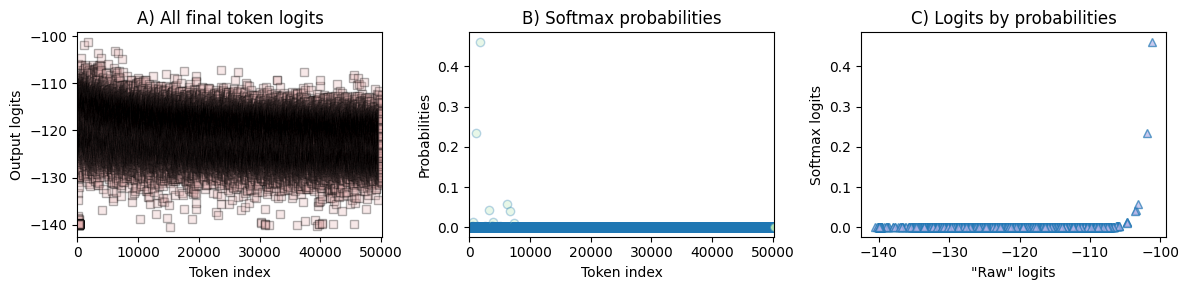

In [34]:
# plot the raw and softmax logits
_,axs = plt.subplots(1,3,figsize=(12,3))

axs[0].plot(logits,'ks',markerfacecolor=[.9,.7,.7,.3])
axs[0].set(xlim=[-10,tokenizer.vocab_size+9],xlabel='Token index',
           ylabel='Output logits',title='A) All final token logits')

axs[1].plot(logits_sm,'o',markerfacecolor=[.7,.9,.7,.3])
axs[1].set(xlim=[-10,tokenizer.vocab_size+9],xlabel='Token index',
           ylabel='Probabilities',title='B) Softmax probabilities')

axs[2].plot(logits,logits_sm,'^',markerfacecolor=[.7,.7,.9,.7])
axs[2].set(xlabel='"Raw" logits',ylabel='Softmax logits',
           title='C) Logits by probabilities')

plt.tight_layout()
plt.show()

In [35]:
# find the maximum
max_logit = logits_sm.argmax()
print(f'The maximum softmax logit is #{max_logit} with a value of {logits_sm[max_logit]:.3f}')
print(f'The max word is "{tokenizer.decode(max_logit)}"')

The maximum softmax logit is #1755 with a value of 0.462
The max word is " night"


In [36]:
max=logits.argmax()

In [37]:
tokenizer.decode(max)

' night'